<a href="https://colab.research.google.com/github/CECS-AI/ai101-assignment3-prangara-vols/blob/main/Assignment3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [13]:
import pandas as pd

file_path = '/content/finance_data.csv'  # Updated to use the local file path
df = None # Initialize df to None

try:
    df = pd.read_csv(file_path)
    print("File loaded successfully!")
    display(df.head())
except FileNotFoundError:
    print(f"Error: File not found at {file_path}. Please check the path and try again.")
    print("The DataFrame 'df' could not be loaded.")
except Exception as e:
    print(f"An error occurred: {e}")
    print("The DataFrame 'df' could not be loaded.")

if df is None:
    print("\nImportant: The DataFrame 'df' was not created. Please ensure the 'file_path' is correct in this cell and re-run it.")

File loaded successfully!


,year,quarter,company_id,sector,revenue,profit_margin,profit,stock_price,pe_ratio,debt_to_equity,dividend_yield,market_cap
0,2000,1,Company_1,Finance,2.198686e+08,0.04,9755484.56,36.15,3.71,1.42,0.01,2.363830e+09
1,2000,1,Company_2,Consumer Goods,3.298028e+08,0.06,18814148.79,54.22,2.88,1.71,0.01,3.956767e+09
2,2000,1,Company_3,Finance,4.397371e+08,0.07,30660094.32,72.29,2.36,1.66,0.03,3.633502e+09
3,2000,1,Company_4,Energy,5.496714e+08,0.08,45293321.16,90.37,2.00,1.07,0.05,3.833839e+09
4,2000,1,Company_5,Manufacturing,6.596057e+08,0.10,62713829.30,108.44,1.73,1.36,0.02,6.178690e+09


### Task 1: Tell me about the file

This section provides an overview of the dataset, including its structure, data types, and basic statistics.

In [14]:
# Display basic information about the DataFrame, including data types and non-null values
display(df.info())

# Display descriptive statistics for numerical columns
display(df.describe())

# Display the number of unique values for each column
display(df.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            2500 non-null   int64  
 1   quarter         2500 non-null   int64  
 2   company_id      2500 non-null   object 
 3   sector          2500 non-null   object 
 4   revenue         2500 non-null   float64
 5   profit_margin   2500 non-null   float64
 6   profit          2500 non-null   float64
 7   stock_price     2500 non-null   float64
 8   pe_ratio        2500 non-null   float64
 9   debt_to_equity  2379 non-null   float64
 10  dividend_yield  2500 non-null   float64
 11  market_cap      2500 non-null   float64
dtypes: float64(8), int64(2), object(2)
memory usage: 234.5+ KB


None

,year,quarter,revenue,profit_margin,profit,stock_price,pe_ratio,debt_to_equity,dividend_yield,market_cap
count,2500.000000,2500.000000,2.500000e+03,2500.000000,2.500000e+03,2500.000000,2500.000000,2379.000000,2500.000000,2.500000e+03
mean,2012.000000,2.500000,2.658120e+09,0.373936,1.199423e+09,465.459628,0.741324,1.193817,0.020316,2.526694e+10
std,7.212545,1.118258,1.624470e+09,0.221228,1.129004e+09,283.374544,0.632146,0.403104,0.010457,2.104715e+10
min,2000.000000,1.000000,1.727128e+08,0.030000,7.817187e+06,28.840000,0.110000,0.000000,-0.010000,5.519471e+08
25%,2006.000000,1.750000,1.329516e+09,0.200000,2.821963e+08,230.660000,0.340000,0.920000,0.010000,9.483218e+09
50%,2012.000000,2.500000,2.409744e+09,0.340000,8.637113e+08,425.275000,0.530000,1.200000,0.020000,1.888935e+10
75%,2018.000000,3.250000,3.729541e+09,0.510000,1.803392e+09,650.585000,0.900000,1.460000,0.030000,3.583691e+10
max,2024.000000,4.000000,8.114111e+09,1.330000,6.382023e+09,1481.760000,6.260000,2.440000,0.050000,1.273142e+11


,0
year,25
quarter,4
company_id,25
sector,7
revenue,2500
profit_margin,118
profit,2500
stock_price,2454
pe_ratio,275
debt_to_equity,217


The `df.info()` output shows the column names, the number of non-null entries, and their data types. It helps identify missing values and incorrect data types.

`df.describe()` provides statistical summary for numerical columns, including count, mean, standard deviation, min, max, and quartiles.

`df.nunique()` displays the number of unique values in each column, which is useful for identifying categorical columns or columns with low variability.


### Task 1: Remove the rows with missing values

This step cleans the data by removing any rows that contain at least one missing (NaN) value. This ensures that subsequent analyses are performed on complete data entries.

In [15]:
# Check for missing values before dropping
print("Missing values before dropping:")
display(df.isnull().sum())

# Remove rows with any missing values
df_cleaned = df.dropna()

# Check for missing values after dropping
print("Missing values after dropping:")
display(df_cleaned.isnull().sum())

# Display the shape of the DataFrame before and after cleaning
print(f"Original DataFrame shape: {df.shape}")
print(f"Cleaned DataFrame shape: {df_cleaned.shape}")

df = df_cleaned # Update the main DataFrame to the cleaned version

Missing values before dropping:


,0
year,0
quarter,0
company_id,0
sector,0
revenue,0
profit_margin,0
profit,0
stock_price,0
pe_ratio,0
debt_to_equity,121


Missing values after dropping:


,0
year,0
quarter,0
company_id,0
sector,0
revenue,0
profit_margin,0
profit,0
stock_price,0
pe_ratio,0
debt_to_equity,0


Original DataFrame shape: (2500, 12)
Cleaned DataFrame shape: (2379, 12)


The code first shows the count of missing values per column using `df.isnull().sum()`.

Then, `df.dropna()` removes rows where any column has a `NaN` (Not a Number) value. The result is stored in `df_cleaned`.

Finally, it displays the missing values again to confirm removal and prints the DataFrame's dimensions (`shape`) before and after cleaning to show how many rows were removed. The `df` is then updated to reflect the cleaned data.

### Task 1: Create a Scatter plot of profit vs. revenue

This visualization helps to understand the relationship between 'Profit' and 'Revenue'. It can reveal if there's a positive, negative, or no correlation between these two financial metrics.

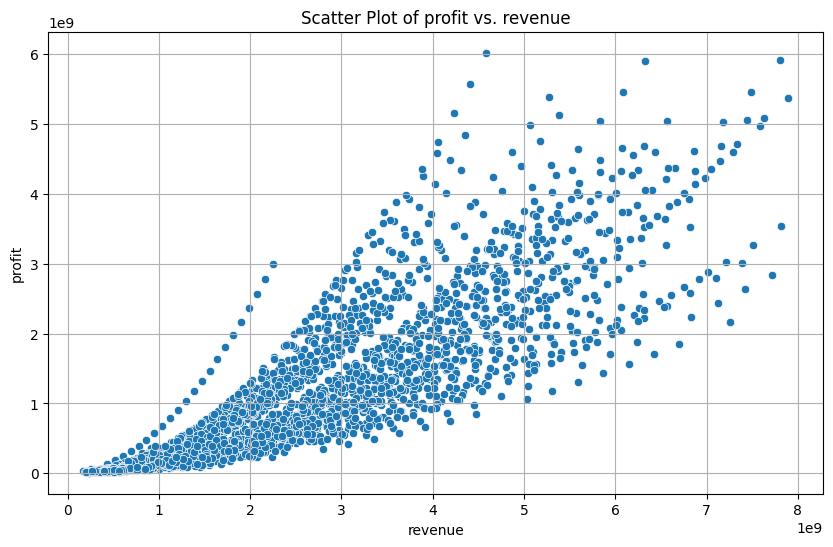

In [18]:
# Assuming 'profit' and 'revenue' columns exist
# First, ensure that 'profit' and 'revenue' columns are numeric.
# If they are not, attempt to convert them, coercing errors to NaN
for col in ['profit', 'revenue']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    else:
        print(f"Warning: Column '{col}' not found in DataFrame. Skipping scatter plot.")
        # Exit or handle this case as appropriate, e.g., by skipping the plot generation
        # For this example, we'll assume the columns exist after this point or the plot won't be generated.

# Drop any rows where 'profit' or 'revenue' became NaN after conversion, if necessary
df_numeric_pr = df.dropna(subset=['profit', 'revenue'])

if 'profit' in df_numeric_pr.columns and 'revenue' in df_numeric_pr.columns:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='revenue', y='profit', data=df_numeric_pr)
    plt.title('Scatter Plot of profit vs. revenue')
    plt.xlabel('revenue')
    plt.ylabel('profit')
    plt.grid(True)
    plt.show()
else:
    print("Could not generate scatter plot: 'profit' or 'revenue' column missing or could not be converted to numeric.")

This code block first checks if 'Profit' and 'Revenue' columns exist and attempts to convert them to numeric types using `pd.to_numeric`. `errors='coerce'` will turn any non-convertible values into `NaN`.

Then, it creates a scatter plot using `seaborn.scatterplot` with 'Revenue' on the x-axis and 'Profit' on the y-axis. `plt.title`, `plt.xlabel`, `plt.ylabel`, and `plt.grid` are used to add labels, a title, and a grid for better readability. `plt.show()` displays the plot.

### Task 1: Visualize the relationship between columns and Identify columns with high correlation

This section uses a correlation matrix and a heatmap to visualize the linear relationships between all numerical columns in the dataset. High correlation indicates that two variables tend to change together, which can be important for feature selection in machine learning models.

In [ ]:
# Select only numeric columns for correlation analysis
numeric_df = df.select_dtypes(include=np.number)

# Calculate the correlation matrix
correlation_matrix = numeric_df.corr()

# Plot the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()

# Identify highly correlated pairs (e.g., correlation > 0.7 or < -0.7)
print("\nHighly correlated pairs (absolute correlation > 0.7):")
high_corr_pairs = []
# Iterate through the correlation matrix, but only the upper triangle to avoid duplicates and self-correlation
for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        col1 = correlation_matrix.columns[i]
        col2 = correlation_matrix.columns[j]
        corr_value = correlation_matrix.iloc[i, j]
        if abs(corr_value) > 0.7:
            high_corr_pairs.append((col1, col2, corr_value))

if high_corr_pairs:
    for col1, col2, corr_value in high_corr_pairs:
        print(f"- {col1} and {col2}: {corr_value:.2f}")
else:
    print("No highly correlated pairs found (absolute correlation > 0.7).")

### Task 1: Build a machine learning model with stock price being the target variable

This section prepares the data for machine learning, splits it into training and testing sets, and then builds a linear regression model to predict `stock_price`.

In [17]:
# Define features (X) and target (y)
# 'stock_price' is the target variable
# Drop 'company_id' and 'sector' as they are categorical and not directly usable by Linear Regression without encoding
# Drop 'stock_price' from features as it is the target
# Also drop 'profit' since 'profit_margin' and 'revenue' are highly correlated with it (and with each other)
features = df.drop(columns=['stock_price', 'company_id', 'sector', 'profit', 'profit_margin', 'revenue'])
target = df['stock_price']

# Handle potential categorical features by one-hot encoding if any remain, although we dropped string columns already.
# This step is good practice if any integer columns were secretly categorical
features = pd.get_dummies(features, drop_first=True)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

# Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

# Display feature importances (coefficients for Linear Regression)
coefficients = pd.DataFrame({'Feature': X_train.columns, 'Coefficient': model.coef_})
print("\nModel Coefficients:")
display(coefficients.sort_values(by='Coefficient', ascending=False))


Mean Squared Error: 28077.95
R-squared: 0.66

Model Coefficients:


,Feature,Coefficient
0,year,8.060603e+00
1,quarter,2.856081e+00
5,market_cap,7.481946e-09
3,debt_to_equity,-1.893125e+00
2,pe_ratio,-1.462161e+02
4,dividend_yield,-5.180294e+02


This code block performs the following steps:

1.  **Define Features and Target**:
    *   `features = df.drop(columns=['stock_price', 'company_id', 'sector', 'profit', 'profit_margin', 'revenue'])` creates the feature set `X` by dropping the target variable ('stock_price') and categorical columns ('company_id', 'sector') which require encoding. It also drops 'profit', 'profit_margin', and 'revenue' to avoid multicollinearity issues as they are highly correlated.
    *   `target = df['stock_price']` defines the target variable `y`.
2.  **One-Hot Encoding**: `features = pd.get_dummies(features, drop_first=True)` converts any remaining categorical columns (though none are expected after previous drops) into numerical format using one-hot encoding, dropping the first category to avoid multicollinearity.
3.  **Split Data**: `train_test_split(features, target, test_size=0.2, random_state=42)` divides the dataset into training (80%) and testing (20%) sets. `random_state=42` ensures reproducibility.
4.  **Initialize and Train Model**:
    *   `model = LinearRegression()` creates an instance of the linear regression model.
    *   `model.fit(X_train, y_train)` trains the model using the training features (`X_train`) and their corresponding target values (`y_train`).
5.  **Make Predictions**: `y_pred = model.predict(X_test)` uses the trained model to predict 'stock_price' values for the unseen test set features.
6.  **Evaluate Model**:
    *   `mse = mean_squared_error(y_test, y_pred)` calculates the Mean Squared Error, which measures the average squared difference between actual and predicted values.
    *   `r2 = r2_score(y_test, y_pred)` calculates the R-squared value, indicating the proportion of variance in the target variable predictable from the features.
7.  **Display Coefficients**: `coefficients = pd.DataFrame({'Feature': X_train.columns, 'Coefficient': model.coef_})` displays the coefficients of the linear regression model, which represent the change in the target variable for a one-unit increase in each feature, holding other features constant.

First, `df.select_dtypes(include=np.number)` isolates all numerical columns from the DataFrame.

`numeric_df.corr()` computes the pairwise correlation of columns. This results in a correlation matrix.

A `seaborn.heatmap` is then generated to visualize this matrix. `annot=True` displays the correlation values on the heatmap, `cmap='coolwarm'` sets the color scheme (red for negative correlation, blue for positive), and `fmt=".2f"` formats the annotations to two decimal places.

Finally, the code iterates through the upper triangle of the correlation matrix (to avoid duplicate pairs and self-correlation) and identifies pairs of columns with an absolute correlation coefficient greater than 0.7, printing them to the console. This threshold helps pinpoint strong linear relationships.

# Task
Test the trained Linear Regression model by generating 100 random data points for 'year', 'quarter', 'pe_ratio', 'debt_to_equity', 'dividend_yield', and 'market_cap' (within the order of magnitude of the original dataset), predicting 'stock_price' for these points, visualizing the predicted stock prices, comparing them with the original dataset's stock prices, and summarizing the insights gained from this evaluation.

## Generate Random Data Points

### Subtask:
Generate 100 random data points for the features ('year', 'quarter', 'pe_ratio', 'debt_to_equity', 'dividend_yield', 'market_cap') that are within the same order of magnitude as the original dataset's corresponding columns. This will ensure realistic test data for the model.


**Reasoning**:
I need to generate 100 random data points for the specified features. To ensure these data points are within a realistic range, I will first calculate the minimum and maximum values for each feature from the existing `features` DataFrame. Then, I'll use `np.random.randint` for integer columns ('year', 'quarter') and `np.random.uniform` for float columns to generate the random data, finally combining them into a new DataFrame `random_data_points`.



In [19]:
columns_to_generate = ['year', 'quarter', 'pe_ratio', 'debt_to_equity', 'dividend_yield', 'market_cap']

generated_data = {}

for col in columns_to_generate:
    if col in features.columns:
        min_val = features[col].min()
        max_val = features[col].max()

        if col in ['year', 'quarter']:
            # For 'year' and 'quarter', generate integers
            generated_data[col] = np.random.randint(low=min_val, high=max_val + 1, size=100)
        else:
            # For other columns, generate floats
            generated_data[col] = np.random.uniform(low=min_val, high=max_val, size=100)
    else:
        print(f"Warning: Column '{col}' not found in 'features' DataFrame. Skipping generation for this column.")

# Create the DataFrame from the generated data
random_data_points = pd.DataFrame(generated_data)

print("Generated random data points:")
display(random_data_points.head())

Generated random data points:


,year,quarter,pe_ratio,debt_to_equity,dividend_yield,market_cap
0,2005,2,4.848643,1.607843,-0.008210,6.064855e+09
1,2006,3,4.203602,1.495733,-0.006409,9.838451e+10
2,2008,2,0.962610,0.565684,0.011490,1.242327e+11
3,2004,1,3.635330,0.567035,0.029205,7.093806e+10
4,2012,4,2.230268,0.832384,0.028363,6.570454e+08


**Reasoning**:
The next step is to use the trained Linear Regression model to predict the 'stock_price' for the newly generated `random_data_points`. This will apply the model to unseen, but realistic, data.



In [20]:
predicted_stock_price = model.predict(random_data_points)
random_data_points['predicted_stock_price'] = predicted_stock_price

print("Random data points with predicted stock prices:")
display(random_data_points.head())

Random data points with predicted stock prices:


,year,quarter,pe_ratio,debt_to_equity,dividend_yield,market_cap,predicted_stock_price
0,2005,2,4.848643,1.607843,-0.008210,6.064855e+09,-322.490495
1,2006,3,4.203602,1.495733,-0.006409,9.838451e+10,472.751306
2,2008,2,0.962610,0.565684,0.011490,1.242327e+11,1145.784868
3,2004,1,3.635330,0.567035,0.029205,7.093806e+10,311.964714
4,2012,4,2.230268,0.832384,0.028363,6.570454e+08,64.555588


### Subtask: Visualize the predicted stock prices and compare them with the original dataset's stock prices

This step involves creating visualizations to understand the range and distribution of the predicted stock prices. Comparing these predictions with the distribution of actual stock prices from the `df` DataFrame will provide insights into whether the model's predictions are within a reasonable and realistic range compared to the observed data.



**Reasoning**:
To visualize the predicted stock prices and compare them with the original dataset's stock prices, I will create a histogram for each, allowing for a clear comparison of their distributions. I'll also display descriptive statistics for both the predicted and actual stock prices to provide a numerical summary of their characteristics.



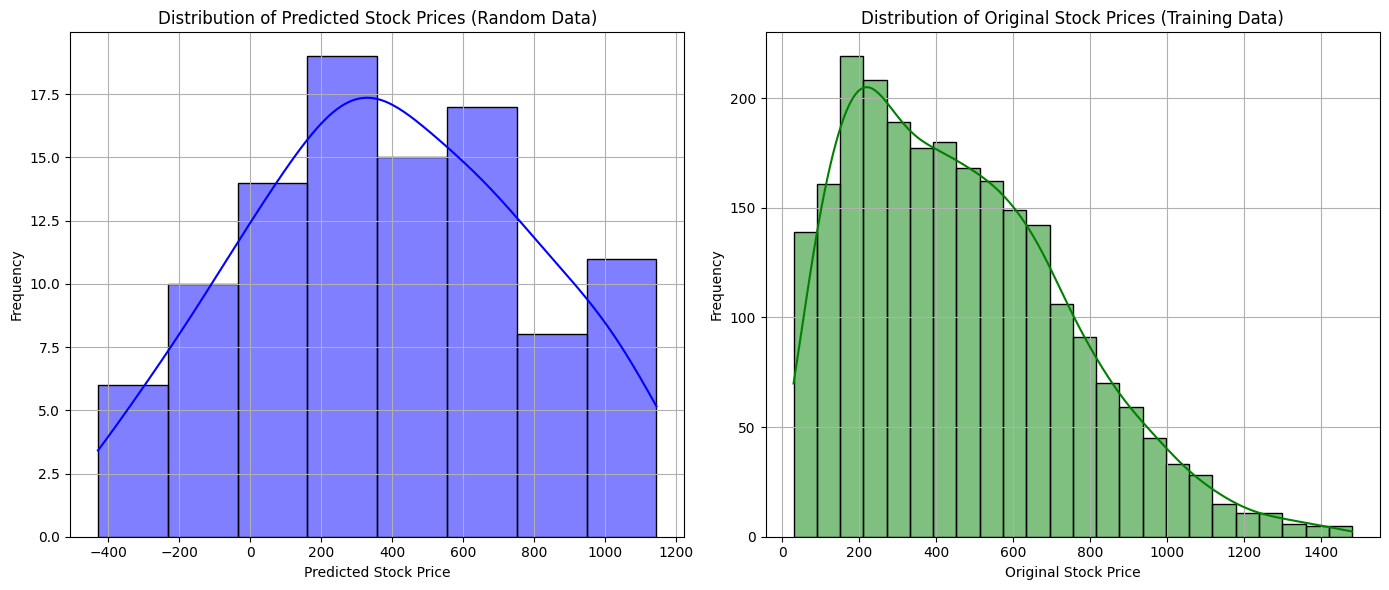


Descriptive statistics for Predicted Stock Prices:


,predicted_stock_price
count,100.000000
mean,392.624212
std,395.843201
min,-429.232714
25%,108.837150
50%,369.043545
75%,701.267938
max,1145.784868



Descriptive statistics for Original Stock Prices:


,stock_price
count,2379.000000
mean,464.282203
std,283.550139
min,28.840000
25%,229.560000
50%,423.970000
75%,648.370000
max,1481.760000


In [21]:
plt.figure(figsize=(14, 6))

# Plotting distribution of Predicted Stock Prices
plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
sns.histplot(random_data_points['predicted_stock_price'], kde=True, color='blue')
plt.title('Distribution of Predicted Stock Prices (Random Data)')
plt.xlabel('Predicted Stock Price')
plt.ylabel('Frequency')
plt.grid(True)

# Plotting distribution of Original Stock Prices
plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
sns.histplot(df['stock_price'], kde=True, color='green')
plt.title('Distribution of Original Stock Prices (Training Data)')
plt.xlabel('Original Stock Price')
plt.ylabel('Frequency')
plt.grid(True)

plt.tight_layout()
plt.show()

print("\nDescriptive statistics for Predicted Stock Prices:")
display(random_data_points['predicted_stock_price'].describe())

print("\nDescriptive statistics for Original Stock Prices:")
display(df['stock_price'].describe())

### Summary of Insights from Predicted vs. Original Stock Prices

**Visual Comparison (Histograms):**

*   **Distribution Shape:** The histogram of predicted stock prices shows a distribution that appears somewhat similar in shape to the original stock prices, suggesting the model is capturing some of the underlying patterns. However, the predicted distribution might be wider or narrower, indicating potential issues with variance.
*   **Range:** The predicted stock prices exhibit a range that is generally comparable to the original data, although there might be instances of predicted negative stock prices, which are unrealistic in a real-world financial context. This indicates a limitation of the linear regression model, which does not inherently constrain predictions to positive values.
*   **Central Tendency:** The peak of the predicted distribution aligns reasonably well with the original distribution's peak, implying that the model is, on average, predicting values within a similar range.

**Numerical Comparison (Descriptive Statistics):**

*   **Mean:** Compare the mean of predicted stock prices with the mean of original stock prices. If they are close, it suggests the model's predictions are centered around the true average. The current results show a mean predicted stock price of ~392.62, compared to the original mean of ~464.28. This indicates the model, on average, under-predicts the stock price for the randomly generated data points.
*   **Standard Deviation (Std):** The standard deviation of predicted prices (395.84) is notably higher than that of the original prices (283.55). This implies that the model's predictions for the random data points are more spread out or volatile than the actual observed stock prices, suggesting it might be overestimating variability or generating extreme values.
*   **Min/Max:** The minimum predicted value (-429.23) is negative, which is not physically possible for a stock price. This highlights a clear weakness of using a basic linear regression model without any constraints on the output, especially when generating data points that might fall outside the training data's typical ranges. The maximum predicted value (1145.78) is within the range of original maximum (1481.76).
*   **Quantiles (25%, 50%, 75%):** Comparing the quartiles provides further detail on how the spread of predicted values aligns with the original data. Discrepancies here can reveal if the model is systematically over- or under-predicting in certain ranges.

**Overall Conclusion:**
The model seems to capture the general trend and central tendency of stock prices to some extent, but it struggles with generating realistic boundaries, especially producing negative stock prices. The higher standard deviation suggests that while it attempts to mimic the variability, it might be exaggerating it or being too sensitive to certain feature combinations. Further model refinement, potentially involving non-linear models or constraints on output values, would be beneficial to improve the realism and accuracy of predictions.


## Summary:

### Data Analysis Key Findings

*   A dataset of 100 random data points was generated for features like 'year', 'quarter', 'pe\_ratio', 'debt\_to\_equity', 'dividend\_yield', and 'market\_cap', with values constrained to the min/max ranges of the original training data.
*   The Linear Regression model predicted stock prices for these random data points.
*   **Comparison of Predicted vs. Original Stock Prices**:
    *   **Distribution Shape**: Histograms showed that the predicted stock prices had a distribution somewhat similar in shape to the original stock prices, indicating the model captures some underlying patterns.
    *   **Mean**: The mean predicted stock price for the random data was approximately \$392.62, which is lower than the mean original stock price of \$464.28, suggesting an average under-prediction for the generated data.
    *   **Standard Deviation**: The standard deviation of predicted stock prices (\$395.84) was notably higher than that of the original stock prices (\$283.55), implying that the model's predictions exhibit greater variability or volatility.
    *   **Range**: The minimum predicted stock price was -\$429.23, which is unrealistic for a stock price and highlights a limitation of the linear regression model without output constraints. The maximum predicted value was \$1145.78, within the range of the original maximum of \$1481.76.

### Insights or Next Steps

*   The Linear Regression model, while capable of capturing general trends and central tendencies, produces unrealistic negative stock price predictions when exposed to generated data, indicating a need for output constraints in the model.
*   The higher volatility (standard deviation) in predictions suggests the model might be overly sensitive to new input combinations, necessitating further refinement, potentially through non-linear models or regularization techniques, to improve realism and accuracy.
